Dataset Shape: (1797, 65)

Data Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1797 entries, 0 to 1796
Data columns (total 65 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   0       1797 non-null   float64
 1   1       1797 non-null   float64
 2   2       1797 non-null   float64
 3   3       1797 non-null   float64
 4   4       1797 non-null   float64
 5   5       1797 non-null   float64
 6   6       1797 non-null   float64
 7   7       1797 non-null   float64
 8   8       1797 non-null   float64
 9   9       1797 non-null   float64
 10  10      1797 non-null   float64
 11  11      1797 non-null   float64
 12  12      1797 non-null   float64
 13  13      1797 non-null   float64
 14  14      1797 non-null   float64
 15  15      1797 non-null   float64
 16  16      1797 non-null   float64
 17  17      1797 non-null   float64
 18  18      1797 non-null   float64
 19  19      1797 non-null   float64
 20  20      1797 non-null   float

C:\Users\varun\AppData\Local\Temp\ipykernel_16212\91375342.py:42: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='label', data=numbers, palette='icefire')


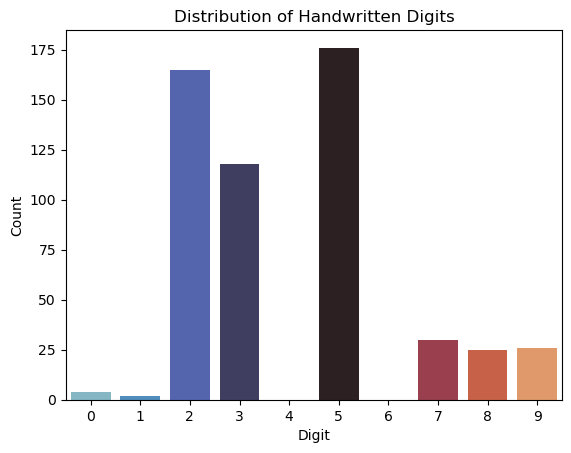

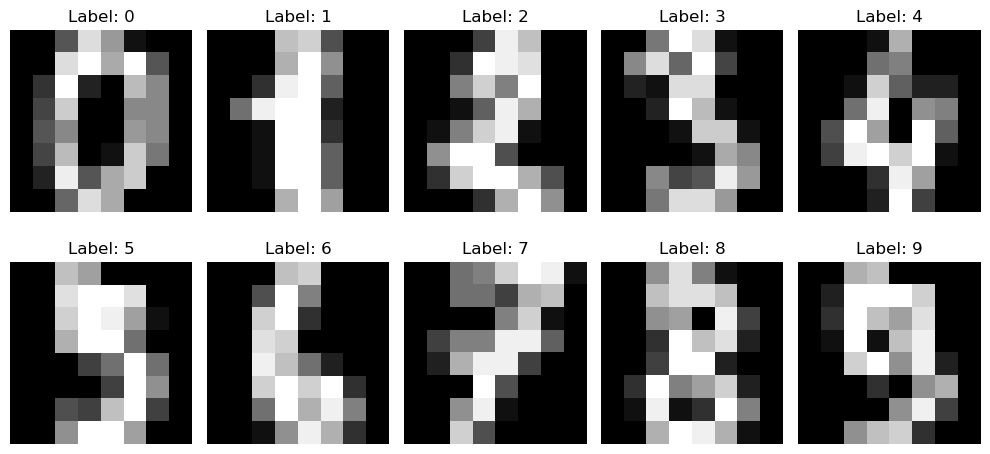


SVM Model Accuracy: 97.5 %


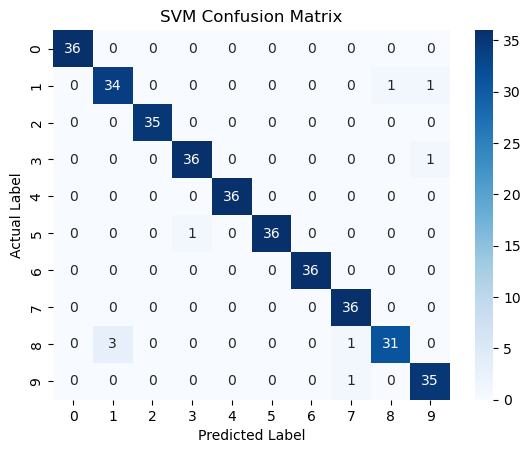


Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        36
           1       0.92      0.94      0.93        36
           2       1.00      1.00      1.00        35
           3       0.97      0.97      0.97        37
           4       1.00      1.00      1.00        36
           5       1.00      0.97      0.99        37
           6       1.00      1.00      1.00        36
           7       0.95      1.00      0.97        36
           8       0.97      0.89      0.93        35
           9       0.95      0.97      0.96        36

    accuracy                           0.97       360
   macro avg       0.98      0.97      0.97       360
weighted avg       0.98      0.97      0.97       360



In [1]:
# Import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Step 1: Load the Digits dataset
digits = datasets.load_digits()

# Step 2: Convert dataset into a DataFrame
# Each image has 64 pixel features and one target label
numbers = pd.DataFrame(digits.data)
numbers['label'] = digits.target

# Step 3: Explore the dataset
print("Dataset Shape:", numbers.shape)

print("\nData Information:")
numbers.info()

print("\nStatistical Description:")
print(numbers.describe())

# Step 4: Check for missing values
print("\nMissing Values:")
print(numbers.isnull().sum())

# Step 5: Check unique digit labels and their counts
print("\nUnique Labels:")
print(np.unique(numbers['label']))

print("\nLabel Counts:")
print(numbers['label'].value_counts().sort_index())

# Step 6: Visualize the distribution of digit labels
sns.countplot(x='label', data=numbers, palette='icefire')
plt.title("Distribution of Handwritten Digits")
plt.xlabel("Digit")
plt.ylabel("Count")
plt.show()

# Step 7: Display some sample handwritten digit images
fig, axes = plt.subplots(2, 5, figsize=(10, 5))

for i, ax in enumerate(axes.flat):
    ax.imshow(digits.images[i], cmap='gray')
    ax.set_title(f"Label: {digits.target[i]}")
    ax.axis('off')

plt.tight_layout()
plt.show()

# Step 8: Separate input features (X) and target labels (y)
X = numbers.drop('label', axis=1)
y = numbers['label']

# Step 9: Scale the input features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Step 10: Split the data into training and testing sets
# 80% data for training and 20% data for testing
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Step 11: Create and train the SVM model using a linear kernel
model_linear = SVC(kernel='linear')
model_linear.fit(X_train, y_train)

# Step 12: Predict the digit labels for test data
y_pred = model_linear.predict(X_test)

# Step 13: Calculate model accuracy
accuracy = accuracy_score(y_test, y_pred)

print("\nSVM Model Accuracy:", accuracy * 100, "%")

# Step 14: Display confusion matrix
cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("SVM Confusion Matrix")
plt.show()

# Step 15: Display classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred))